In [157]:
import os 
import pandas as pd 
import numpy as np
from scipy.stats import bootstrap
import seaborn as sns 
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectFpr
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split, cross_val_score
from sklearn.feature_selection import RFE
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler, LabelBinarizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB

Cell below completes 1(abc): files are accessed through directory instead of through API call. For 1(c)(i), beyond simple measures of central tendency such as mean or IQR, common features include root mean square (RMS), autocorrelation (ACF), and entropy.  

In [101]:
cols = ["time","avg_rss12","var_rss12","avg_rss13","var_rss13","avg_rss23","var_rss23"]
test_list = ["b11.csv", "b12.csv", "b21.csv", "b22.csv", "l1.csv", "l2.csv", "l2.csv", "c1.csv", "c2.csv", "c3.csv", "w1.csv", "w2.csv", "w3.csv", "si1.csv", "si2.csv", "si3.csv", "st1.csv", "st2.csv", "st3.csv"]
feature_cols = ["min", "max", "mean", "median", "sd", "q1", "q3"]
feature_cols = [f"{item}_{i+1}" for i in range(6) for item in feature_cols]
train_df = pd.DataFrame(columns=cols)
train_y = pd.DataFrame(columns=['activity'])
test_df = pd.DataFrame(columns=cols)
test_y = pd.DataFrame(columns=['activity'])
feature_df = pd.DataFrame(columns=feature_cols)
for file in os.listdir('./AReM'): 
    df = pd.read_csv(f'AReM/{file}', sep=None, engine='python', comment='#')
    if df.shape[1] == 8: 
        df = pd.read_csv(f'AReM/{file}', sep=r'\s+', comment="#")
    df.columns = cols
    if file in test_list: 
        test_df = pd.concat([test_df, df])
        test_y = pd.concat([test_y, pd.DataFrame([f'{file}']*df.shape[0], columns=['activity'])])
    else: 
        train_df = pd.concat([train_df, df])
        train_y = pd.concat([train_y, pd.DataFrame([f'{file}']*df.shape[0], columns=['activity'])])
    features = [] 
    for i in df.columns: 
        if i == "time": 
            continue
        feature_list = [df[i].min(), df[i].max(), df[i].mean(), df[i].median(), df[i].std(), df[i].quantile(0.25), df[i].quantile(0.75)]
        features.extend(feature_list)
    temp_df = pd.DataFrame([features], columns=feature_cols)
    feature_df = pd.concat([feature_df, temp_df])
for i in feature_df.columns: 
    sd = feature_df[i].std() 
    vals = (feature_df[i].values, )
    res = bootstrap(vals, np.std, confidence_level=0.90, random_state=32)
    #print(f'Standard Deviation of {i}: {sd}, 90% CI: ({res.confidence_interval.low}, {res.confidence_interval.high})')


C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\3633738591.py:16: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  test_df = pd.concat([test_df, df])
C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\3633738591.py:28: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  feature_df = pd.concat([feature_df, temp_df])
C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\3633738591.py:19: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, thi

For 1(c)(iv), I think the three most important time domain features across all six time series is mean, median, and q3, as they have the largest standard deviation across all six time series which means there should be a lot of variation between groups. 

All code and markdown cells above complete HW 3. All code and markdown cells below complete HW 4. 

The code block below completes 2(a)(i). 

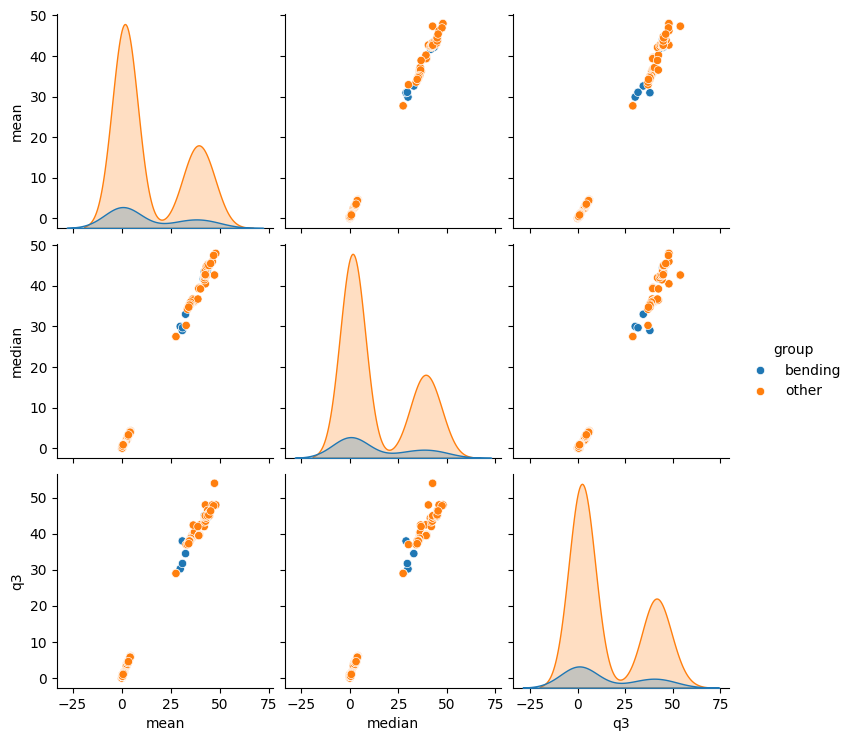

In [102]:
mean_data = [] 
median_data = [] 
q3_data = [] 
group_data = [] 
for i in train_y['activity'].unique(): 
    df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
    if df.shape[1] == 8: 
        df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
    df.columns = cols
    for j in ['avg_rss12', 'var_rss12', 'var_rss23']: 
        mean_data.append(df[j].mean()) 
        median_data.append(df[j].median())
        q3_data.append(df[j].quantile(0.75))
        if i[0] == 'b': 
            group_data.append('bending') 
        else: 
            group_data.append('other')
pair_df = pd.DataFrame({'mean': mean_data, 'median': median_data, 'q3': q3_data, 'group': group_data})
sns.pairplot(pair_df, hue='group')
plt.show()


The code block below completes 2(a)(ii). 

c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\_core\fromnumeric.py:57: FutureWarning: 'Series.swapaxes' is deprecated and will be removed in a future version. Please use 'Series.transpose' instead.
  return bound(*args, **kwds)
c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\_core\fromnumeric.py:57: FutureWarning: 'Series.swapaxes' is deprecated and will be removed in a future version. Please use 'Series.transpose' instead.
  return bound(*args, **kwds)
c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\_core\fromnumeric.py:57: FutureWarning: 'Series.swapaxes' is deprecated and will be removed in a future version. Please use 'Series.transpose' instead.
  return bound(*args, **kwds)
c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\_core\fromnumeric.py:57: FutureWarning: 'Series.swapaxes' is deprecated and will be removed in a future version. Please use 'Series.transp

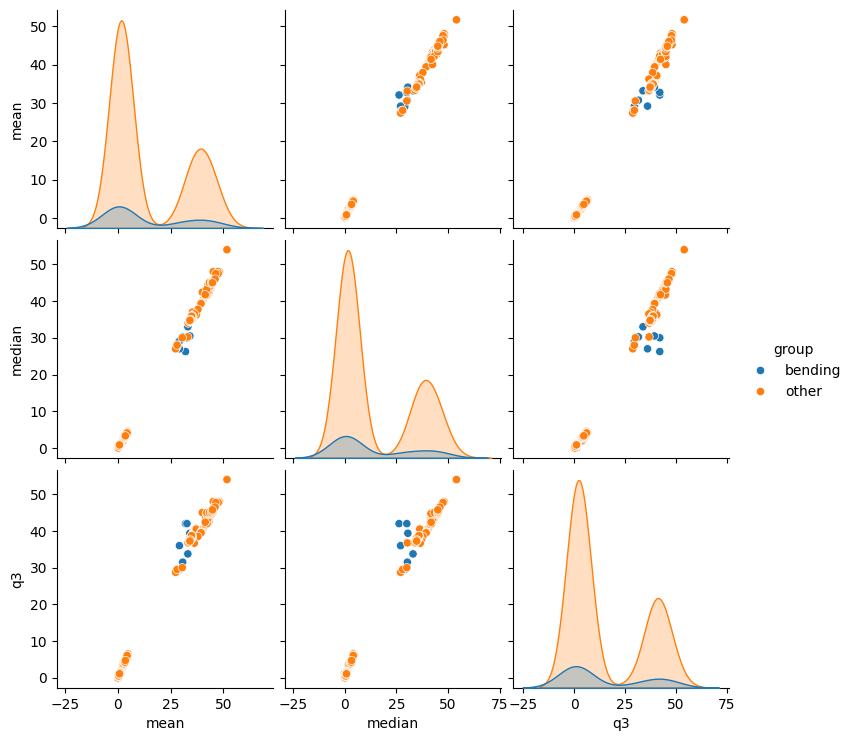

In [103]:
mean_data2 = [] 
median_data2 = [] 
q3_data2 = [] 
group_data2 = [] 
for i in train_y['activity'].unique(): 
    df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
    if df.shape[1] == 8: 
        df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
    df.columns = cols
    for j in ['avg_rss12', 'var_rss12', 'var_rss23']: 
        chunks = np.array_split(df[j], 2)
        for k in chunks: 
            mean_data2.append(k.mean()) 
            median_data2.append(k.median())
            q3_data2.append(k.quantile(0.75))
            if i[0] == 'b': 
                group_data2.append('bending') 
            else: 
                group_data2.append('other')
pair_df = pd.DataFrame({'mean': mean_data2, 'median': median_data2, 'q3': q3_data2, 'group': group_data2})
sns.pairplot(pair_df, hue='group')
plt.show()

For question 2(a)(ii), splitting each time series in half immediately shows two separate groups of 'bending' in the scatterplots. These two groups are presumably the front half and back half of a bending action. 

The code blocks below complete 2(a)(iii) to the best of my understanding, as the question was worded vaguely. I first did feature selection using sklearn.feature_selection outside of CV and then did CV with RFE inside the CV loop. 

In [104]:
for l in range(1, 21): 
    feature_df = pd.DataFrame(columns=range(l*18))
    feature_y = [] 
    for i in train_y['activity'].unique(): 
        df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
        if df.shape[1] == 8: 
            df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
        df.columns = cols
        feature_list = [] 
        for j in df.columns:
            if j == 'time': 
                continue  
            chunks = np.array_split(df[j].to_numpy(), l)
            for k in chunks: 
                feature_list.append(k.mean())
                feature_list.append(np.median(k)) 
                feature_list.append(np.quantile(k, 0.75))
        feature_df = pd.concat([feature_df, pd.DataFrame([feature_list])])
        if i[0] == 'b': 
            feature_y.append(1) 
        else: 
            feature_y.append(0)
    feature_df_new = SelectFpr().fit_transform(feature_df, feature_y)
    print(feature_df.shape)
    print(feature_df_new.shape)
    model = LogisticRegression(max_iter=20).fit(feature_df_new, feature_y)
    train_acc = model.score(feature_df_new, feature_y)
    print(f'Training accuracy for pruned features with l = {l}: {train_acc}')

    



C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\3506247316.py:18: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  feature_df = pd.concat([feature_df, pd.DataFrame([feature_list])])


(70, 18)
(70, 12)
Training accuracy for pruned features with l = 1: 0.9428571428571428


c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\3506247316.py:18: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  feature_df = pd.concat([feature_df, pd.DataFrame([feature_list])])


(70, 36)
(70, 23)
Training accuracy for pruned features with l = 2: 0.9857142857142858


c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\3506247316.py:18: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  feature_df = pd.concat([feature_df, pd.DataFrame([feature_list])])


...

c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\3506247316.py:18: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  feature_df = pd.concat([feature_df, pd.DataFrame([feature_list])])


(70, 342)
(70, 184)
Training accuracy for pruned features with l = 19: 1.0


c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\3506247316.py:18: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  feature_df = pd.concat([feature_df, pd.DataFrame([feature_list])])


(70, 360)
(70, 197)
Training accuracy for pruned features with l = 20: 1.0


c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


For 2(a)(iii), it is clear that simple feature selection for high dimensional feature spaces results in highly unstable models, and even restricting the max_iters parameter severely does not stop the model from being instable (train accuracy = 1.0). Below is the second half of 2(a)(iii), which uses cross-validation with recursive feature elimination to determine the best number of features for each l. The correct way to use cross-validation is to do all the feature selection, including the RFE, inside the cross-validation loop (i.e., only on 80% of the data in any one pass) so that there is no data leakage. The wrong way to do it is to do RFE and any othewr feature selection prior to cross-validation of the model given (l, p) as that allows the model to see the entire training dataset before CV, which is a form of data leakage. 

In [106]:
best_num_features = [] 
best_scores = [] 
for l in range(1, 21): 
    feature_df = pd.DataFrame(columns=range(l*18))
    feature_y = [] 
    for i in train_y['activity'].unique(): 
        df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
        if df.shape[1] == 8: 
            df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
        df.columns = cols
        feature_list = [] 
        for j in df.columns:
            if j == 'time': 
                continue  
            chunks = np.array_split(df[j].to_numpy(), l)
            for k in chunks: 
                feature_list.append(k.mean())
                feature_list.append(np.median(k)) 
                feature_list.append(np.quantile(k, 0.75))
        feature_df = pd.concat([feature_df, pd.DataFrame([feature_list])])
        if i[0] == 'b': 
            feature_y.append(1) 
        else: 
            feature_y.append(0)
    pipeline = Pipeline([
        ('rfe', RFE(estimator=LogisticRegression(max_iter=20))),
        ('classifier', LogisticRegression(max_iter=20))
    ])
    param_grid = {
        'rfe__n_features_to_select': range(1, l*18 + 1)
    }
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=32)
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=cv,
        scoring='roc_auc',  
        n_jobs=-1,
        verbose=1
    )
    grid_search.fit(feature_df, feature_y)
    best_num_features.append(grid_search.best_params_['rfe__n_features_to_select'])
    best_scores.append(grid_search.best_score_)
best_l = best_scores.index(max(best_scores)) + 1 
best_p = best_num_features[best_scores.index(max(best_scores))]
print(f'Best (l, p): ({best_l}, {best_p}')
    


C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\2244438295.py:20: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  feature_df = pd.concat([feature_df, pd.DataFrame([feature_list])])


Fitting 5 folds for each of 18 candidates, totalling 90 fits


c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/st

Fitting 5 folds for each of 36 candidates, totalling 180 fits


c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/st

...

c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/st

Fitting 5 folds for each of 360 candidates, totalling 1800 fits


c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/st

Best (l, p): (3, 5


c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/st

In [107]:
print(best_num_features)
print(best_scores)

[16, 17, 5, 5, 5, 1, 2, 6, 1, 1, 5, 5, 4, 4, 5, 2, 9, 1, 5, 1]
[np.float64(0.9916666666666668), np.float64(0.9833333333333332), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0)]


For 2(a), we will only use stable models. Therefore the best model is where the data series is not chunked and there are 16/18 features retained after RFE. The below code block completes 2(a)(iv). 

C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\2229425572.py:15: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  feature_df2 = pd.concat([feature_df2, pd.DataFrame([feature_list])])


(70, 18)


c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/st

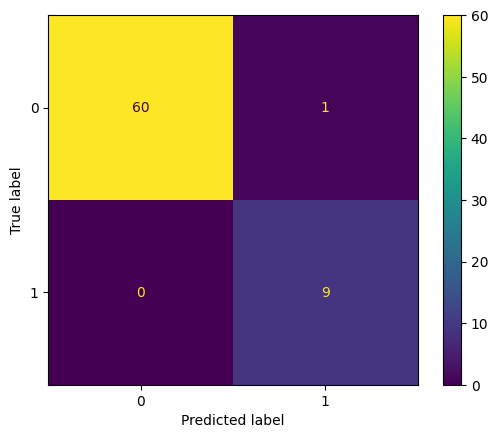

0.9981785063752276


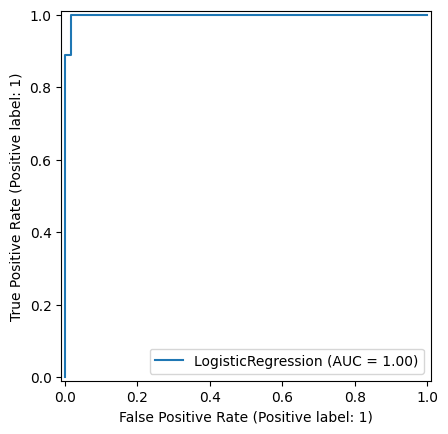

Optimization terminated successfully    (Exit mode 0)
            Current function value: 9.170986218943532e-11
            Iterations: 41
            Function evaluations: 48
            Gradient evaluations: 41
[  1.13315221   9.11516286 -29.28396674  -9.14451691  10.4643039
 -24.7234088  -15.9267508   10.46496396  -6.74962314 -12.22203136
  -7.2672521   43.2790922  -26.28855653  28.94939461  -4.39699373
  -7.81548674  -9.34940341]
[ 1.  1. nan nan nan  1.  1.  1. nan nan nan  1.  1. nan  1. nan nan]


In [120]:
feature_df2 = pd.DataFrame(columns=range(18))
feature_y2 = [] 
for i in train_y['activity'].unique(): 
    df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
    if df.shape[1] == 8: 
        df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
    df.columns = cols
    feature_list = [] 
    for j in df.columns:
        if j == 'time': 
            continue  
        feature_list.append(df[j].mean())
        feature_list.append(df[j].median())
        feature_list.append(df[j].quantile(0.75))
    feature_df2 = pd.concat([feature_df2, pd.DataFrame([feature_list])])
    if i[0] == 'b': 
        feature_y2.append(1) 
    else: 
        feature_y2.append(0)
print(feature_df2.shape)
rfe = RFE(estimator=LogisticRegression(max_iter=20), n_features_to_select=16)
rfe_data = rfe.fit_transform(feature_df2, feature_y2)
model = LogisticRegression(max_iter=20)
model.fit(rfe_data, feature_y2)
y_probs = model.predict_proba(rfe_data)[:, 1]
y_pred = model.predict(rfe_data)
# confusion matrix 
cm = confusion_matrix(feature_y2, y_pred, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()
# ROC AUC score 
auc_score = roc_auc_score(feature_y2, y_probs)
print(auc_score)
# ROC graph 
RocCurveDisplay.from_estimator(model, rfe_data, feature_y2)
plt.show()
# use statsmodels.api Logit model to extract parameters and p values 
sm_data = sm.add_constant(rfe_data)
model2 = sm.Logit(feature_y2, sm_data)
results = model2.fit_regularized() # need regularized because of singular matrices
print(results.params)
print(results.pvalues)

The following code block completes 2(a)(v). 

C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\4188065456.py:15: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  feature_df3 = pd.concat([feature_df3, pd.DataFrame([feature_list])])


1.0


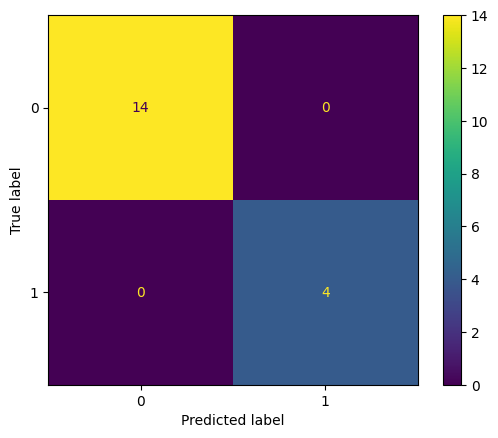

In [128]:
feature_df3 = pd.DataFrame(columns=range(18))
feature_y3 = [] 
for i in test_y['activity'].unique(): 
    df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
    if df.shape[1] == 8: 
        df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
    df.columns = cols
    feature_list = [] 
    for j in df.columns:
        if j == 'time': 
            continue  
        feature_list.append(df[j].mean())
        feature_list.append(df[j].median())
        feature_list.append(df[j].quantile(0.75))
    feature_df3 = pd.concat([feature_df3, pd.DataFrame([feature_list])])
    if i[0] == 'b': 
        feature_y3.append(1) 
    else: 
        feature_y3.append(0)
rfe_data2 = rfe.transform(feature_df3)
test_pred = model.predict(rfe_data2)
test_auc = roc_auc_score(feature_y3, test_pred)
print(test_auc) 
cm2 = confusion_matrix(feature_y3, test_pred, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm2)
disp.plot()
plt.show()

The train AUC score was 0.9981785063752276. The test AUC score of 1.0 makes me think that this is a linearly separable class and that this model is not necessarily stable either. This markdown cell answers 2(a)(v-vi). 

For 2(a)(vii), yes, the classes appear to be imbalanced. The true proportion is 75:13 which is about 5.8:1, so it is past the 5:1 threshold. Therefore, it is necessary to sample 65 of the 74 non-bending instances (i.e., the controls) and keep all 13 of the bending instances (i.e., the cases), before splitting them into train and test sets. Furthermore, it is necessary to adjust its B0. The following code blcok completes 2(a)(vii). 

[np.str_('c12.csv'), np.str_('w11.csv'), np.str_('si12.csv'), np.str_('w10.csv'), np.str_('c11.csv'), np.str_('si13.csv'), np.str_('si4.csv'), np.str_('si3.csv'), np.str_('w13.csv'), np.str_('l13.csv'), np.str_('st11.csv'), np.str_('w5.csv'), np.str_('si10.csv'), np.str_('w14.csv'), np.str_('c3.csv'), np.str_('w15.csv'), np.str_('l7.csv'), np.str_('st3.csv'), np.str_('st6.csv'), np.str_('l1.csv'), np.str_('c8.csv'), np.str_('c7.csv'), np.str_('w6.csv'), np.str_('si15.csv'), np.str_('c5.csv'), np.str_('st4.csv'), np.str_('w1.csv'), np.str_('l15.csv'), np.str_('l11.csv'), np.str_('st2.csv'), np.str_('st12.csv'), np.str_('si9.csv'), np.str_('si14.csv'), np.str_('c15.csv'), np.str_('st9.csv'), np.str_('l12.csv'), np.str_('w7.csv'), np.str_('si6.csv'), np.str_('si2.csv'), np.str_('si11.csv'), np.str_('st7.csv'), np.str_('l3.csv'), np.str_('st10.csv'), np.str_('st8.csv'), np.str_('l14.csv'), np.str_('l8.csv'), np.str_('c9.csv'), np.str_('w9.csv'), np.str_('l6.csv'), np.str_('c13.csv'), np.st

C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\2810440749.py:32: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  feature_df4 = pd.concat([feature_df4, pd.DataFrame([feature_list])])
c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\eilee\AppData\

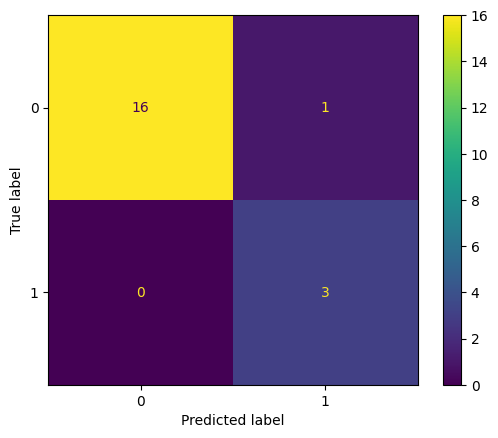

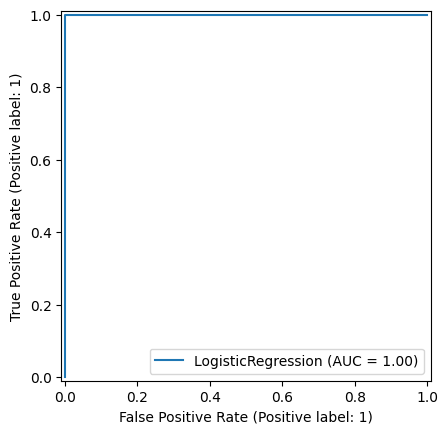

In [141]:
cases = [] 
controls = [] 
for file in os.listdir('./AReM'): 
    if file[0] == 'b': 
        cases.append(file)
    else: 
        controls.append(file)

downsample = list(np.random.choice(controls, size=65, replace=False))
print(downsample)
print(cases)
downsample.extend(cases)
labels = [0]*65 + [1]*13 
print(downsample) 
print(labels)
X_train, X_test, y_train, y_test = train_test_split(downsample, labels, stratify=labels, random_state=32)

feature_df4 = pd.DataFrame(columns=range(18))

for i in X_train: 
    df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
    if df.shape[1] == 8: 
        df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
    df.columns = cols
    feature_list = [] 
    for j in df.columns:
        if j == 'time': 
            continue  
        feature_list.append(df[j].mean())
        feature_list.append(df[j].median())
        feature_list.append(df[j].quantile(0.75))
    feature_df4 = pd.concat([feature_df4, pd.DataFrame([feature_list])])

model3 = LogisticRegression(max_iter=20)
model3.fit(feature_df4, y_train) 

pi_pop = 13/88
pi_sample = 0.2 
correction = np.log(pi_pop / (1 - pi_pop)) - np.log(pi_sample / (1 - pi_sample))

model3.intercept_ = model3.intercept_ + correction

feature_df5 = pd.DataFrame(columns=range(18))

for i in X_test: 
    df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
    if df.shape[1] == 8: 
        df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
    df.columns = cols
    feature_list = [] 
    for j in df.columns:
        if j == 'time': 
            continue  
        feature_list.append(df[j].mean())
        feature_list.append(df[j].median())
        feature_list.append(df[j].quantile(0.75))
    feature_df5 = pd.concat([feature_df5, pd.DataFrame([feature_list])])

y_pred3 = model3.predict(feature_df5)
auc = roc_auc_score(y_test, y_pred3)
cm3 = confusion_matrix(y_test, y_pred3, labels=model3.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm3)
disp.plot()
plt.show()
RocCurveDisplay.from_estimator(model3, feature_df5, y_test)
plt.show()

The below code blocks complete 2(b)(i). 

In [143]:
best_lambda = [] 
scores = [] 
for l in range(1, 21): 
    feature_df = pd.DataFrame(columns=range(l*18))
    feature_y = [] 
    for i in train_y['activity'].unique(): 
        df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
        if df.shape[1] == 8: 
            df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
        df.columns = cols
        feature_list = [] 
        for j in df.columns:
            if j == 'time': 
                continue  
            chunks = np.array_split(df[j].to_numpy(), l)
            for k in chunks: 
                feature_list.append(k.mean())
                feature_list.append(np.median(k)) 
                feature_list.append(np.quantile(k, 0.75))
        feature_df = pd.concat([feature_df, pd.DataFrame([feature_list])])
        if i[0] == 'b': 
            feature_y.append(1) 
        else: 
            feature_y.append(0)
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegressionCV(
            Cs=10,             
            penalty='l1',               
            solver='liblinear',           
            cv=5,                        
            random_state=32,
        ))
    ])
    pipeline.fit(feature_df, feature_y)
    best_score_index = np.argmax(np.mean(pipeline.named_steps['clf'].scores_[1], axis=0))
    best_score = np.max(np.mean(pipeline.named_steps['clf'].scores_[1], axis=0))
    best_C = pipeline.named_steps['clf'].Cs_[best_score_index]
    best_lambda.append(best_C)
    scores.append(best_score)

C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\3644221750.py:20: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  feature_df = pd.concat([feature_df, pd.DataFrame([feature_list])])
C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\3644221750.py:20: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  feature_df = pd.concat([feature_df, pd.DataFrame([feature_list])])
C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\3644221750.py:20: FutureWarning: The behavior of DataFrame concatenation with empty or a

In [144]:
print(best_lambda)
print(scores)

[np.float64(2.782559402207126), np.float64(0.3593813663804626), np.float64(0.3593813663804626), np.float64(0.3593813663804626), np.float64(0.3593813663804626), np.float64(0.3593813663804626), np.float64(0.3593813663804626), np.float64(0.3593813663804626), np.float64(0.3593813663804626), np.float64(2.782559402207126), np.float64(0.3593813663804626), np.float64(0.3593813663804626), np.float64(0.3593813663804626), np.float64(0.3593813663804626), np.float64(166.81005372000558), np.float64(166.81005372000558), np.float64(0.3593813663804626), np.float64(0.3593813663804626), np.float64(21.54434690031882), np.float64(0.3593813663804626)]
[np.float64(0.9285714285714286), np.float64(0.9428571428571428), np.float64(0.9571428571428573), np.float64(0.9571428571428573), np.float64(0.9571428571428573), np.float64(0.9571428571428573), np.float64(0.9428571428571428), np.float64(0.9428571428571428), np.float64(0.9428571428571428), np.float64(0.9571428571428573), np.float64(0.9428571428571428), np.float6

For 2(b)(ii), the L1 penalized model did better than the p-value selection one as it no longer looks like the model is unstable. Furthermore, the L1 penalized model is easier and faster to implement. 

The below code block completes 2(c)(i). Multinomial logistic regression confusion matrices are implemented identically to binary matrices and are simply n x n instead of 2 x 2, where n is the number of labels. Since ROC curves are binary by nature, it is possible to either do pairwise ROC curves between every pair of classes, or to do one-vs-rest for each class. Since liblinear uses one-vs-rest, that is what I will do for the ROC curves of multinomial classification. 

In [146]:
best_multi_lambda = [] 
multi_scores = [] 
for l in range(1, 21): 
    feature_df = pd.DataFrame(columns=range(l*18))
    feature_y = [] 
    for i in train_y['activity'].unique(): 
        df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
        if df.shape[1] == 8: 
            df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
        df.columns = cols
        feature_list = [] 
        for j in df.columns:
            if j == 'time': 
                continue  
            chunks = np.array_split(df[j].to_numpy(), l)
            for k in chunks: 
                feature_list.append(k.mean())
                feature_list.append(np.median(k)) 
                feature_list.append(np.quantile(k, 0.75))
        feature_df = pd.concat([feature_df, pd.DataFrame([feature_list])])
        if i[0:2] == 'si': 
            feature_y.append(0)
        elif i[0:2] == 'st': 
            feature_y.append(1)
        elif i[0] == 'b': 
            feature_y.append(2)
        elif i[0] == 'c': 
            feature_y.append(3)
        elif i[0] == 'l': 
            feature_y.append(4)
        else: 
            feature_y.append(5)
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegressionCV(
            Cs=10,             
            penalty='l1',               
            solver='liblinear',  
            multi_class='ovr',          
            cv=5,                        
            random_state=32,
        ))
    ])
    pipeline.fit(feature_df, feature_y)
    best_score_index = np.argmax(np.mean(pipeline.named_steps['clf'].scores_[1], axis=0))
    best_score = np.max(np.mean(pipeline.named_steps['clf'].scores_[1], axis=0))
    best_C = pipeline.named_steps['clf'].Cs_[best_score_index]
    best_multi_lambda.append(best_C)
    multi_scores.append(best_score)

C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\692690844.py:20: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  feature_df = pd.concat([feature_df, pd.DataFrame([feature_list])])
c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1914: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegressionCV(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\692690844.py:20: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns wh

In [147]:
print(best_multi_lambda)
print(multi_scores)

[np.float64(2.782559402207126), np.float64(2.782559402207126), np.float64(2.782559402207126), np.float64(2.782559402207126), np.float64(2.782559402207126), np.float64(2.782559402207126), np.float64(2.782559402207126), np.float64(2.782559402207126), np.float64(2.782559402207126), np.float64(2.782559402207126), np.float64(2.782559402207126), np.float64(2.782559402207126), np.float64(2.782559402207126), np.float64(0.3593813663804626), np.float64(2.782559402207126), np.float64(0.3593813663804626), np.float64(0.3593813663804626), np.float64(0.3593813663804626), np.float64(0.3593813663804626), np.float64(0.3593813663804626)]
[np.float64(0.8857142857142858), np.float64(0.8857142857142858), np.float64(0.8571428571428571), np.float64(0.8571428571428571), np.float64(0.8428571428571429), np.float64(0.9), np.float64(0.8571428571428571), np.float64(0.8571428571428571), np.float64(0.8714285714285713), np.float64(0.8571428571428571), np.float64(0.8857142857142858), np.float64(0.8857142857142858), np.

It appears that the best l is 6 with C 2.782559402207126 for multinomial regression. 

C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\2157656460.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  multi_feature_df = pd.concat([multi_feature_df, pd.DataFrame([feature_list])])
c:\Users\eilee\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\2157656460.py:49: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-N

0.10970568783068779


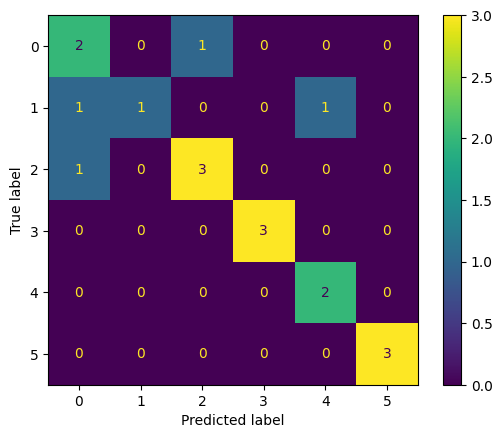

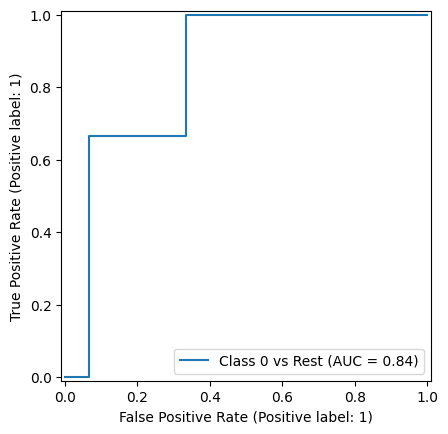

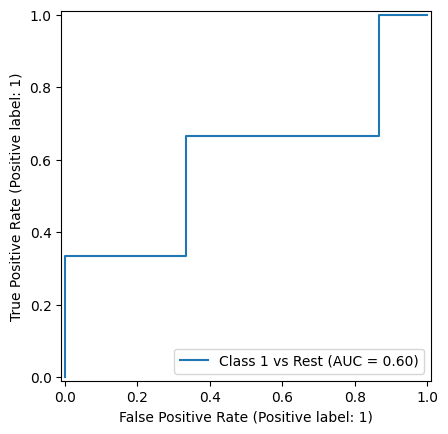

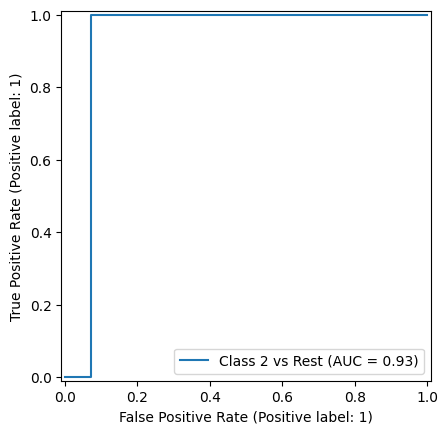

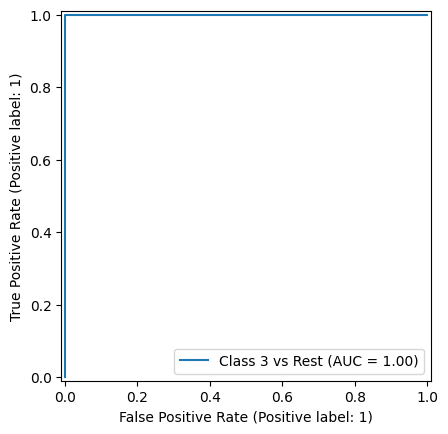

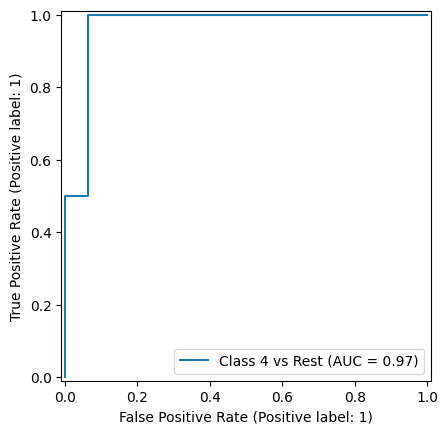

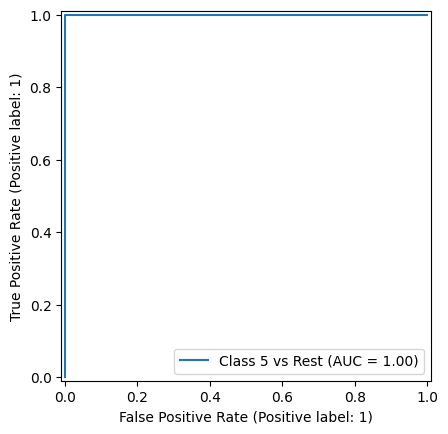

In [155]:
multi_feature_df = pd.DataFrame(columns=range(6*18))
multi_feature_y = [] 
for i in train_y['activity'].unique(): 
    df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
    if df.shape[1] == 8: 
        df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
    df.columns = cols
    feature_list = [] 
    for j in df.columns:
        if j == 'time': 
            continue  
        chunks = np.array_split(df[j].to_numpy(), 6)
        for k in chunks: 
            feature_list.append(k.mean())
            feature_list.append(np.median(k)) 
            feature_list.append(np.quantile(k, 0.75))
    multi_feature_df = pd.concat([multi_feature_df, pd.DataFrame([feature_list])])
    if i[0:2] == 'si': 
        multi_feature_y.append(0)
    elif i[0:2] == 'st': 
        multi_feature_y.append(1)
    elif i[0] == 'b': 
        multi_feature_y.append(2)
    elif i[0] == 'c': 
        multi_feature_y.append(3)
    elif i[0] == 'l': 
        multi_feature_y.append(4)
    else: 
        multi_feature_y.append(5)
multi_model = LogisticRegression(multi_class='ovr', C=2.782559402207126, solver='liblinear')
multi_model.fit(multi_feature_df, multi_feature_y)

multi_test_df = pd.DataFrame(columns=range(6*18))
multi_test_y = [] 
for i in test_y['activity'].unique(): 
    df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
    if df.shape[1] == 8: 
        df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
    df.columns = cols
    feature_list = [] 
    for j in df.columns:
        if j == 'time': 
            continue  
        chunks = np.array_split(df[j].to_numpy(), 6)
        for k in chunks: 
            feature_list.append(k.mean())
            feature_list.append(np.median(k)) 
            feature_list.append(np.quantile(k, 0.75))
    multi_test_df = pd.concat([multi_test_df, pd.DataFrame([feature_list])])
    if i[0:2] == 'si': 
        multi_test_y.append(0)
    elif i[0:2] == 'st': 
        multi_test_y.append(1)
    elif i[0] == 'b': 
        multi_test_y.append(2)
    elif i[0] == 'c': 
        multi_test_y.append(3)
    elif i[0] == 'l': 
        multi_test_y.append(4)
    else: 
        multi_test_y.append(5)

multi_pred = multi_model.predict(multi_test_df)
multi_proba = multi_model.predict_proba(multi_test_df)

labelbin = LabelBinarizer().fit(multi_feature_y)
labelbin_y = labelbin.transform(multi_test_y)

auc = roc_auc_score(multi_test_y, multi_proba, multi_class='ovr')
print(1 - auc)
cm4 = confusion_matrix(multi_test_y, multi_pred, labels=multi_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm4)
disp.plot()
plt.show()
for class_idx, class_label in enumerate(labelbin.classes_):
    RocCurveDisplay.from_predictions(
        labelbin_y[:, class_idx],
        multi_proba[:, class_idx],
        name=f"Class {class_label} vs Rest"
    )
    plt.show()

For 2(c)(i), the test error is 0.10970568783068779. 

The below code block completes 2(c)(ii). Since there is no C parameter in Naive Bayes models, the best model will simply be the highest performing l-chunking with CV using cross_val_score. 

In [158]:
gaussian_scores = [] 
multinb_scores = [] 
gaussian_model = GaussianNB() 
multinb_model = MultinomialNB() 
for l in range(1, 21): 
    feature_df = pd.DataFrame(columns=range(l*18))
    feature_y = [] 
    for i in train_y['activity'].unique(): 
        df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
        if df.shape[1] == 8: 
            df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
        df.columns = cols
        feature_list = [] 
        for j in df.columns:
            if j == 'time': 
                continue  
            chunks = np.array_split(df[j].to_numpy(), l)
            for k in chunks: 
                feature_list.append(k.mean())
                feature_list.append(np.median(k)) 
                feature_list.append(np.quantile(k, 0.75))
        feature_df = pd.concat([feature_df, pd.DataFrame([feature_list])])
        if i[0:2] == 'si': 
            feature_y.append(0)
        elif i[0:2] == 'st': 
            feature_y.append(1)
        elif i[0] == 'b': 
            feature_y.append(2)
        elif i[0] == 'c': 
            feature_y.append(3)
        elif i[0] == 'l': 
            feature_y.append(4)
        else: 
            feature_y.append(5)
    gaussian_cv_score = cross_val_score(gaussian_model, feature_df, feature_y)
    multinb_cv_score = cross_val_score(multinb_model, feature_df, feature_y)
    gaussian_scores.append(gaussian_cv_score)
    multinb_scores.append(multinb_cv_score)

C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\1534656595.py:22: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  feature_df = pd.concat([feature_df, pd.DataFrame([feature_list])])
C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\1534656595.py:22: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  feature_df = pd.concat([feature_df, pd.DataFrame([feature_list])])
C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\1534656595.py:22: FutureWarning: The behavior of DataFrame concatenation with empty or a

In [164]:
gaussian_scores = np.array(gaussian_scores).mean(axis=1)
multinb_scores = np.array(multinb_scores).mean(axis=1)
print(gaussian_scores)
print(multinb_scores)

[0.8        0.78571429 0.78571429 0.78571429 0.84285714 0.77142857
 0.82857143 0.78571429 0.82857143 0.82857143 0.82857143 0.77142857
 0.8        0.81428571 0.81428571 0.74285714 0.77142857 0.78571429
 0.77142857 0.77142857]
[0.85714286 0.85714286 0.87142857 0.85714286 0.87142857 0.87142857
 0.87142857 0.82857143 0.82857143 0.84285714 0.82857143 0.82857143
 0.81428571 0.82857143 0.81428571 0.82857143 0.84285714 0.82857143
 0.82857143 0.82857143]


It seems like the best l for Gaussian naive bayes is 5, while many different l values achieved the same highest score for Multinomial naive bayes, the smallest of which is 3. 

C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\3665862035.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  gaussian_feature_df = pd.concat([gaussian_feature_df, pd.DataFrame([feature_list])])
C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\3665862035.py:47: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  multinb_feature_df = pd.concat([multinb_feature_df, pd.DataFrame([feature_list])])
C:\Users\eilee\AppData\Local\Temp\ipykernel_18956\3665862035.py:80: FutureWarning: The behavior of DataF

0.014814814814814725


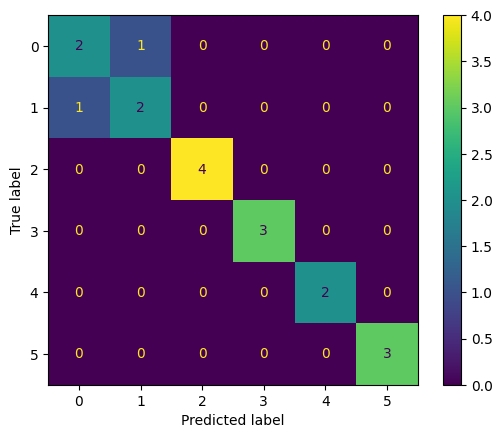

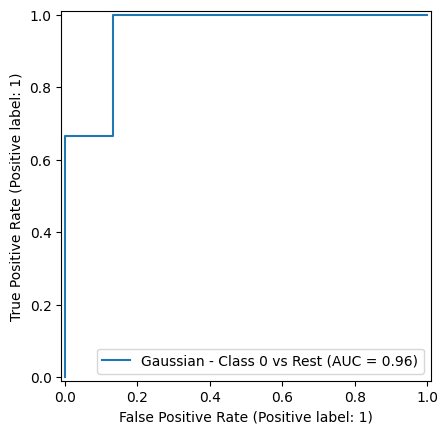

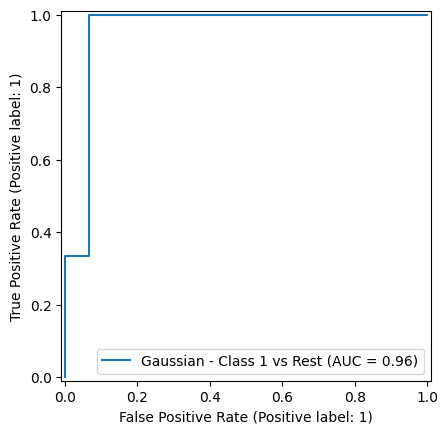

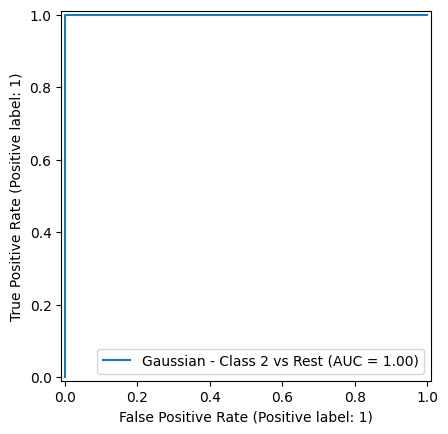

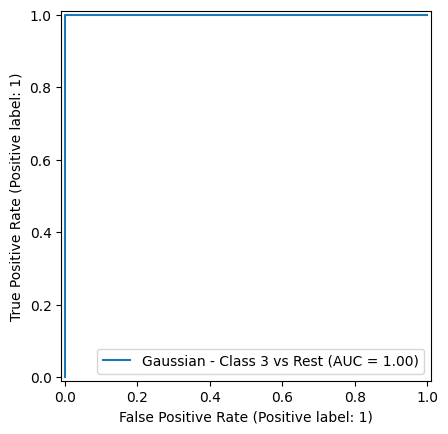

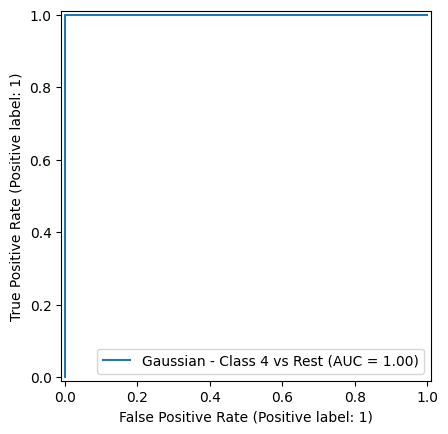

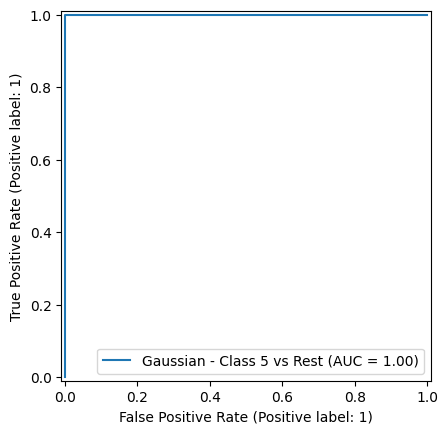

0.007407407407407418


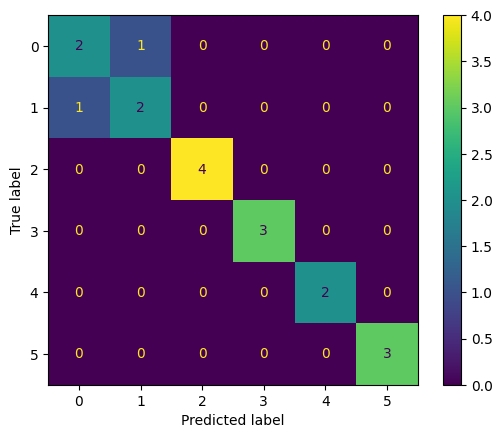

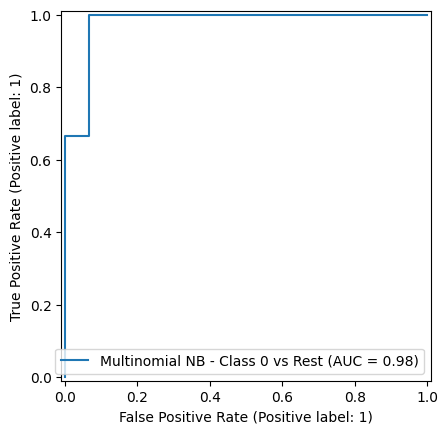

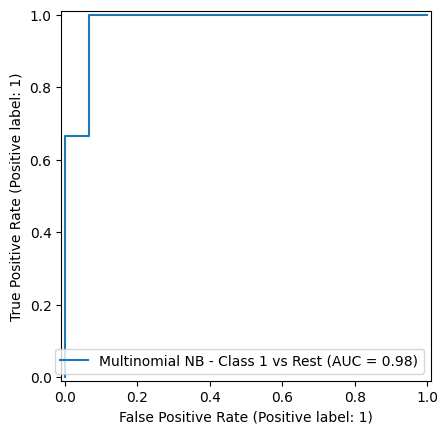

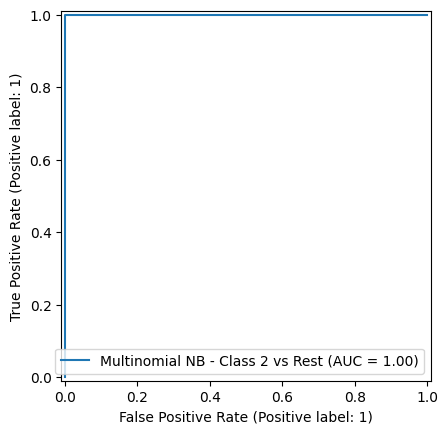

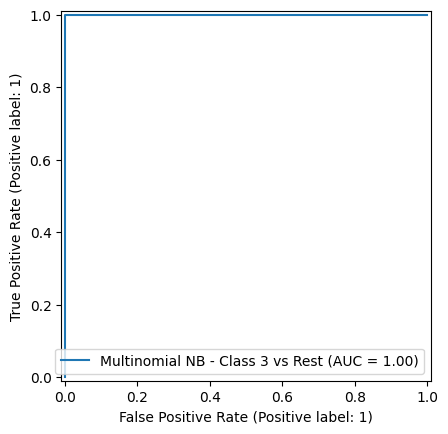

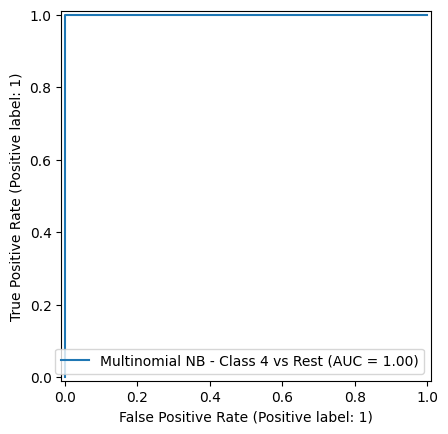

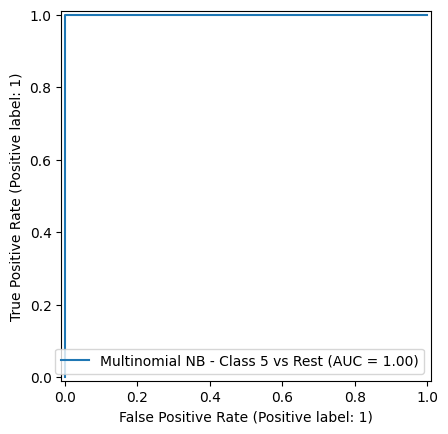

In [165]:
gaussian_feature_df = pd.DataFrame(columns=range(5*18))
gaussian_feature_y = [] 
for i in train_y['activity'].unique(): 
    df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
    if df.shape[1] == 8: 
        df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
    df.columns = cols
    feature_list = [] 
    for j in df.columns:
        if j == 'time': 
            continue  
        chunks = np.array_split(df[j].to_numpy(), 5)
        for k in chunks: 
            feature_list.append(k.mean())
            feature_list.append(np.median(k)) 
            feature_list.append(np.quantile(k, 0.75))
    gaussian_feature_df = pd.concat([gaussian_feature_df, pd.DataFrame([feature_list])])
    if i[0:2] == 'si': 
        gaussian_feature_y.append(0)
    elif i[0:2] == 'st': 
        gaussian_feature_y.append(1)
    elif i[0] == 'b': 
        gaussian_feature_y.append(2)
    elif i[0] == 'c': 
        gaussian_feature_y.append(3)
    elif i[0] == 'l': 
        gaussian_feature_y.append(4)
    else: 
        gaussian_feature_y.append(5)

multinb_feature_df = pd.DataFrame(columns=range(3*18))
multinb_feature_y = [] 
for i in train_y['activity'].unique(): 
    df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
    if df.shape[1] == 8: 
        df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
    df.columns = cols
    feature_list = [] 
    for j in df.columns:
        if j == 'time': 
            continue  
        chunks = np.array_split(df[j].to_numpy(), 3)
        for k in chunks: 
            feature_list.append(k.mean())
            feature_list.append(np.median(k)) 
            feature_list.append(np.quantile(k, 0.75))
    multinb_feature_df = pd.concat([multinb_feature_df, pd.DataFrame([feature_list])])
    if i[0:2] == 'si': 
        multinb_feature_y.append(0)
    elif i[0:2] == 'st': 
        multinb_feature_y.append(1)
    elif i[0] == 'b': 
        multinb_feature_y.append(2)
    elif i[0] == 'c': 
        multinb_feature_y.append(3)
    elif i[0] == 'l': 
        multinb_feature_y.append(4)
    else: 
        multinb_feature_y.append(5)

gaussian_model.fit(gaussian_feature_df, gaussian_feature_y) 
multinb_model.fit(multinb_feature_df, multinb_feature_y)

gaussian_test_df = pd.DataFrame(columns=range(5*18))
gaussian_test_y = [] 
for i in test_y['activity'].unique(): 
    df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
    if df.shape[1] == 8: 
        df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
    df.columns = cols
    feature_list = [] 
    for j in df.columns:
        if j == 'time': 
            continue  
        chunks = np.array_split(df[j].to_numpy(), 5)
        for k in chunks: 
            feature_list.append(k.mean())
            feature_list.append(np.median(k)) 
            feature_list.append(np.quantile(k, 0.75))
    gaussian_test_df = pd.concat([gaussian_test_df, pd.DataFrame([feature_list])])
    if i[0:2] == 'si': 
        gaussian_test_y.append(0)
    elif i[0:2] == 'st': 
        gaussian_test_y.append(1)
    elif i[0] == 'b': 
        gaussian_test_y.append(2)
    elif i[0] == 'c': 
        gaussian_test_y.append(3)
    elif i[0] == 'l': 
        gaussian_test_y.append(4)
    else: 
        gaussian_test_y.append(5)

multinb_test_df = pd.DataFrame(columns=range(3*18))
multinb_test_y = [] 
for i in test_y['activity'].unique(): 
    df = pd.read_csv(f'AReM/{i}', sep=None, engine='python', comment='#')
    if df.shape[1] == 8: 
        df = pd.read_csv(f'AReM/{i}', sep=r'\s+', comment="#") 
    df.columns = cols
    feature_list = [] 
    for j in df.columns:
        if j == 'time': 
            continue  
        chunks = np.array_split(df[j].to_numpy(), 3)
        for k in chunks: 
            feature_list.append(k.mean())
            feature_list.append(np.median(k)) 
            feature_list.append(np.quantile(k, 0.75))
    multinb_test_df = pd.concat([multinb_test_df, pd.DataFrame([feature_list])])
    if i[0:2] == 'si': 
        multinb_test_y.append(0)
    elif i[0:2] == 'st': 
        multinb_test_y.append(1)
    elif i[0] == 'b': 
        multinb_test_y.append(2)
    elif i[0] == 'c': 
        multinb_test_y.append(3)
    elif i[0] == 'l': 
        multinb_test_y.append(4)
    else: 
        multinb_test_y.append(5)

gaussian_pred = gaussian_model.predict(gaussian_test_df)
gaussian_proba = gaussian_model.predict_proba(gaussian_test_df)
multinb_pred = multinb_model.predict(multinb_test_df)
multinb_proba = multinb_model.predict_proba(multinb_test_df)

gaussian_labelbin = LabelBinarizer().fit(gaussian_feature_y)
gaussian_labelbin_y = gaussian_labelbin.transform(gaussian_test_y)
multinb_labelbin = LabelBinarizer().fit(multinb_feature_y)
multinb_labelbin_y = multinb_labelbin.transform(multinb_test_y)

auc = roc_auc_score(gaussian_test_y, gaussian_proba, multi_class='ovr')
print(1 - auc)
cm5 = confusion_matrix(gaussian_test_y, gaussian_pred, labels=gaussian_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm5)
disp.plot()
plt.show()
for class_idx, class_label in enumerate(gaussian_labelbin.classes_):
    RocCurveDisplay.from_predictions(
        gaussian_labelbin_y[:, class_idx],
        gaussian_proba[:, class_idx],
        name=f"Gaussian - Class {class_label} vs Rest"
    )
    plt.show()

auc = roc_auc_score(multinb_test_y, multinb_proba, multi_class='ovr')
print(1 - auc)
cm6 = confusion_matrix(multinb_test_y, multinb_pred, labels=multinb_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm6)
disp.plot()
plt.show()
for class_idx, class_label in enumerate(multinb_labelbin.classes_):
    RocCurveDisplay.from_predictions(
        multinb_labelbin_y[:, class_idx],
        multinb_proba[:, class_idx],
        name=f"Multinomial NB - Class {class_label} vs Rest"
    )
    plt.show()

For 2(c)(ii), the confusion matrices and the ROC curves look the same between the Gaussian and Multinomial naive bayes models. However, for 2(c)(iii), the Multinomial NB model is still better to use, as it was able to achieve a lower test error and higher test ROC AUC score. 